# One Asics runner from raw c3d: our reanalysis, and how far the old MATLAB was from it

Chapter 5, page 1 of 3. Previous: [RBDS, 39 runners vs their Visual3D](rbds_report.ipynb).
Next: [the math of the three legacy errors](legacy_error_math.ipynb), then
[legacy equations on P1 walking](p1_asics.ipynb).

This is the actual reanalysis. One runner (S1) from the Asics shoe study, shoe AM,
trial RP: raw c3d files in, joint torques out, and then the *same two files*
pushed through the old lab MATLAB so we can see what it got and why. If you want
to see this exact code on a body where the answer is known first, that's
[squat-to-stand through the real pipeline](tutorial_s2s_markers.ipynb) (its analysis
cells are copied from this page).

We are going to demonstrate the following key steps in the inverse dynamics workflow:

1. Weigh and calibrate the runner from the standing static trial: joint centres, segment frames, cluster shapes, body mass (§3–4).
2. Load the running trial and carry those joint centres through it as virtual points on SVD cluster fits (§5–7).
3. Check that the marker clusters stay rigid, and decide contact by contact which foot hit the belt (§8).
4. Solve inverse dynamics for foot, shank, thigh and pelvis, and audit the energy balance (§9–11).
5. Run the old MATLAB's inverse dynamics, ported line by line, on the same files and compare events, COP and moments (§12–14).
6. Climb a ladder from their equations to ours, one fix per rung (§15).
7. Run the *original* MATLAB and show the port matches it to round-off (§16).
8. Build the interactive viewer and the report page (§17–19).

This notebook reports on the following key findings about our reanalysis:

1. The static plate weighs S1 at 49.8 kg, and the clusters hold their standing shape while running: mean fit residual 0.80 / 0.58 / 1.00 mm for foot / shank / thigh, and 9.03 mm for the pelvis (it carries the skin-mounted GT markers) (§4, §8).
2. Both feet land on the same belt, and COP distance sorts them cleanly: right-foot contacts sit 0.050–0.055 m from the right-foot markers, left-foot ones 0.298–0.312 m away (first five contacts). That leaves 43 right steps (§8, §11).
3. The energy balance closes: interior imbalance 0.369 W RMS, 1.278 W peak, 0.4 % of peak dE/dt (§10, report Fig. 8).
4. Mean stance sagittal torques peak at 126.9 / 91.8 / 59.6 N m at ankle / knee / hip, about 2.6 / 1.9 / 1.2 N m/kg (§14, report Fig. 3).
5. On the same 17 stances, the MATLAB's exported moments have the right shape (r = 0.988 / 0.99 / 0.933) but sit 7.5 / 7.0 / 10.8 N m RMS from ours, and they under-read the knee (82.1 vs 91.8 N m) and hip (53.1 vs 59.6 N m) peaks. The ankle agrees (126.2 vs 126.9 N m) (§14).
6. Fixing only the three equations plus the free-moment axis brings that down to 6.1 / 5.9 / 6.0 N m. Filtering the markers first doesn't close the hip (8.6 N m); what's left is modelling choices, mostly anthropometrics (Vaughan's thigh is 5.2 kg, de Leva's 7.1 kg). The MATLAB's after-the-fact 12 Hz filter was doing a lot of work: raw hip peak 123 N m, 67 N m once filtered (§15).
7. Events agree to a few frames: legacy minus ours is −8.0 ± 2.1 ms at heel strike and +10.9 ± 6.7 ms at toe off (42 vs 43 stances) (§13).
8. The port *is* the MATLAB: MATLAB R2024b gives identical events and moments within 6.0e-11 N m of the port (§16).
9. Treating the foot as rigid overstates net ankle work by +2.3 J per step (24 % of the net): ankle joint +30.7 / −21.1 J per stance, the distal foot adds +3.7 / −6.0 J (report Fig. 5).

How to use it: run the cells in order, everything stays in memory, add cells and
poke around. For another shoe or trial change §2 and rerun. For array shapes I use
**T** = motion frames, **Ta** = analog samples, **S** = segments, **J** = joints,
**P** = force plates. Meters unless I say otherwise.

## Part 1 — our pipeline on the raw c3d

## 1 — Import the analysis tools

Load the functions, and find the repo whether you started Jupyter from the root or from `notebooks/`.

In [1]:
from pathlib import Path
from IPython.display import HTML, display
import matplotlib.pyplot as plt
import numpy as np

from boneid.core import AnalysisParams, energy_audit, inverse_dynamics
from boneid.io_c3d import build_chain, calibrate_static, load_c3d
from boneid.report import c3d_report_html, c3d_viewer_html, right_step_events

# The report module selects Agg for file rendering; restore notebook figure output.
%matplotlib inline

ROOT = Path.cwd()
if not (ROOT / "data").is_dir():
    ROOT = ROOT.parent
print(f"Repository: {ROOT}")


Repository: /Users/jeremy/Git/brent/bonelab_inverse_dynamics


## 2 — Choose the study settings

Everything below reads these. `SEX` picks the de Leva table; it's an assumption on my part, because sex isn't recorded in this export. Ground moments are taken about a fixed lab origin. `BODY_MASS_KG = None` means the static force plate weighs the subject.

In [2]:
DATA_DIR = ROOT / "data" / "asics"
SUBJECT = "S1"
CONDITION = "AM"                # AG / AH / AM
TRIAL = "RP"                    # PI / RP
SEX = "male"
BODY_MASS_KG = None            # None: weigh the subject on the static plate
CONTACT_THRESHOLD_N = 50.0
KINEMATIC_LOWPASS_HZ = 12.0
TREADMILL_ORIGIN = np.zeros(3)

print(f"Static: {DATA_DIR / f'{SUBJECT}_{CONDITION}_Static.c3d'}")
print(f"Dynamic: {DATA_DIR / f'{SUBJECT}_{CONDITION}_{TRIAL}.c3d'}")


Static: /Users/jeremy/Git/brent/bonelab_inverse_dynamics/data/asics/S1_AM_Static.c3d
Dynamic: /Users/jeremy/Git/brent/bonelab_inverse_dynamics/data/asics/S1_AM_RP.c3d


## 3 — Weigh and calibrate, part 1: load the standing trial

`load_c3d` gives back a `C3dTrial`: marker trajectories, force-plate signals, plate geometry, and separate motion and analog clocks, all SI. Look at `static.markers` or `static.force` in a new cell if you're curious.

In [3]:
static = load_c3d(DATA_DIR / f"{SUBJECT}_{CONDITION}_Static.c3d")
display({"type": type(static).__name__, "motion_frames": len(static.t),
         "motion_rate_hz": static.rate, "analog_rate_hz": static.analog_rate,
         "marker_count": len(static.markers), "force_shape_Ta_P_xyz": static.force.shape})


{'type': 'C3dTrial',
 'motion_frames': 300,
 'motion_rate_hz': 300.0,
 'analog_rate_hz': 3000.0,
 'marker_count': 26,
 'force_shape_Ta_P_xyz': (3000, 2, 3)}

## 4 — Weigh and calibrate, part 2: who the subject is

`calibrate_static` returns a `StaticCalibration`: joint centres and anatomical frames measured while standing, the shape of each marker cluster, body mass (from the static plate: 49.8 kg here), and segment lengths.

Why a static trial at all? The medial ankle and knee markers are only on for standing; they come off before running. So the standing pose is where we measure the joint centres, and during running those centres ride along as **virtual points** on the cluster poses (the Söderkvist & Wedin SVD fit). I kept the old lab's conventions: hip centre = 0.70·RGT + 0.30·LGT, knee and ankle centres at the medial/lateral midpoints.

In [4]:
cal = calibrate_static(static, sex=SEX, body_mass=BODY_MASS_KG)
display({"type": type(cal).__name__, "side": cal.side,
         "body_mass_kg": cal.body_mass, "segment_lengths_m": cal.lengths,
         "joint_centers_and_endpoints_m": cal.points})


{'type': 'StaticCalibration',
 'side': 'r',
 'body_mass_kg': 49.82098054139314,
 'segment_lengths_m': {'foot': 0.2183333042832416,
  'shank': 0.3413323152598963,
  'thigh': 0.41445923422496256,
  'pelvis': 0.059194975798264354,
  'forefoot_width': 0.10655453777568724},
 'joint_centers_and_endpoints_m': {'ankle': array([0.27595234, 1.20909949, 0.08310348]),
  'knee': array([0.3022858, 1.1733447, 0.421535 ]),
  'hip': array([0.34972511, 1.11857251, 0.82961094]),
  'hip_l': array([0.48471228, 1.10001984, 0.83303933]),
  'mid_hip': array([0.41721869, 1.10929618, 0.83132514]),
  'l5s1': array([0.4212555 , 1.14192099, 0.88055288]),
  'heel': array([0.2671188 , 1.25533211, 0.01780919]),
  'toe': array([0.261343  , 1.0878928 , 0.01219486]),
  'toebox': array([0.27047443, 1.03750911, 0.03234585])}}

## 5 — Load the running trial

The running `C3dTrial` has the cleaned-up marker trajectories (label swaps repaired, de-spiked) plus lab-frame force, COP and free moment acting on the subject.

In [5]:
trial = load_c3d(DATA_DIR / f"{SUBJECT}_{CONDITION}_{TRIAL}.c3d")
display({"type": type(trial).__name__, "motion_frames": len(trial.t),
         "motion_rate_hz": trial.rate, "analog_rate_hz": trial.analog_rate,
         "force_shape_Ta_P_xyz": trial.force.shape,
         "marker_names": sorted(trial.markers)})  


{'type': 'C3dTrial',
 'motion_frames': 8699,
 'motion_rate_hz': 300.0,
 'analog_rate_hz': 3000.0,
 'force_shape_Ta_P_xyz': (86990, 2, 3),
 'marker_names': ['AnkleLat',
  'DorsalFoot',
  'HeelLat',
  'HeelMed',
  'KneeLat',
  'LASIS',
  'LGT',
  'LPSIS',
  'MTP1Head',
  'MTP5Head',
  'RASIS',
  'RGT',
  'RPSIS',
  'ShankAntProx',
  'ShankPostDist',
  'ShankPostProx',
  'ThighAntProx',
  'ThighPostDist',
  'ThighPostProx',
  'ToeboxAnt',
  'ToeboxLat',
  'ToeboxMed']}

## 6 — Set the analysis parameters

`AnalysisParams` holds the filter and contact settings. I use the same low-pass cutoff for forces and kinematics, because mismatched cutoffs make ugly impact artifacts in the joint moments. Nothing gets filtered yet.

In [6]:
params = AnalysisParams(contact_threshold_n=CONTACT_THRESHOLD_N,
                        lowpass_hz=KINEMATIC_LOWPASS_HZ,
                        force_lowpass_hz=KINEMATIC_LOWPASS_HZ)
display(params)


AnalysisParams(gravity=array([ 0.  ,  0.  , -9.81]), contact_threshold_n=50.0, lowpass_hz=12.0, force_lowpass_hz=12.0, filter_order=4, treadmill_speed=0.0, flag_crossover=False)

## 7 — Carry the joint centres through the run: build the right-leg chain

`build_chain` returns four things: `skeleton` (segment properties), `kin` (segment poses on the motion clock), `ground` (the right-foot wrench), and `quality` (cluster-fit and contact-attribution diagnostics). The static calibration gets carried through every frame by the cluster fits. Both feet land on the same belt, so it also decides contact by contact which foot it was.

In [7]:
skeleton, kin, ground, quality = build_chain(
    trial, cal, point=TREADMILL_ORIGIN, threshold_n=CONTACT_THRESHOLD_N)
display({"segments": skeleton.segment_names, "joints": skeleton.joint_names,
         "segment_mass_kg": skeleton.mass, "segment_length_m": skeleton.length,
         "kin_r_world_shape_T_S_3_3": kin.r_world.shape,
         "ground_force_shape_T_xyz": ground.force.shape,
         "ground_moment_shape_T_xyz": ground.moment.shape,
         "quality_fields": list(quality)})


{'segments': ['foot', 'shank', 'thigh', 'pelvis'],
 'joints': ['ankle', 'knee', 'hip'],
 'segment_mass_kg': array([0.68254743, 2.15724846, 7.05465084, 5.56500353]),
 'segment_length_m': array([0.2183333 , 0.34133232, 0.41445923, 0.05919498]),
 'kin_r_world_shape_T_S_3_3': (8699, 4, 3, 3),
 'ground_force_shape_T_xyz': (8699, 3),
 'ground_moment_shape_T_xyz': (8699, 3),
 'quality_fields': ['cluster_residual', 'bouts', 'points']}

## 8 — Check the cluster fit, and which contacts are the right foot

Two checks before any torques, both in `quality`.

**Do the markers move like a rigid segment?** For every running frame the static cluster shape is rotated and translated to best match the measured markers. The **cluster-fit residual** is the RMS distance left over, per frame per segment. The cell averages it over time, in mm. Bigger means more mismatch and is worth a look. But it can't tell you *why*, a small residual does **not** mean the joint centres are right, and a time average can hide short spikes.

**Which contacts belong to the right foot?** Only the right leg is modelled, but both feet hit the instrumented belt. A **bout** is one detected contact:

| Field | Meaning |
|---|---|
| `plate` | Force-plate index, starting at zero. |
| `t_on`, `t_off` | Contact start and end, in seconds. |
| `cop_dist_m` | Mean horizontal distance (m) between the COP and the centre of the right-foot markers, over the part of contact above half the peak vertical force. |
| `mine` | `True`: right foot, include its force. `False`: leave it out. |

The rule is **distance < 0.25 m**, a geometric guess, not a measured foot label. Bouts peaking below 250 N get thrown out first (that's the belt ringing). The cell shows the first five; `quality["bouts"]` has all of them.

In [8]:
display({"mean_cluster_residual_mm": dict(zip(
    skeleton.segment_names, 1000 * np.nanmean(quality["cluster_residual"], axis=0)))})
display(quality["bouts"][:5])


{'mean_cluster_residual_mm': {'foot': np.float64(0.8043239644400632),
  'shank': np.float64(0.5846410568093003),
  'thigh': np.float64(1.0036370233330552),
  'pelvis': np.float64(9.026652153174844)}}

[{'plate': 1,
  't_on': np.float64(0.101),
  't_off': np.float64(0.31433333333333335),
  'mine': False,
  'cop_dist_m': 0.3124833572659633},
 {'plate': 1,
  't_on': np.float64(0.44266666666666665),
  't_off': np.float64(0.6506666666666666),
  'mine': True,
  'cop_dist_m': 0.05045499861558278},
 {'plate': 1,
  't_on': np.float64(0.7696666666666667),
  't_off': np.float64(0.9943333333333333),
  'mine': False,
  'cop_dist_m': 0.2975387286764188},
 {'plate': 1,
  't_on': np.float64(1.106),
  't_off': np.float64(1.3263333333333334),
  'mine': True,
  'cop_dist_m': 0.054957842242882346},
 {'plate': 1,
  't_on': np.float64(1.45),
  't_off': np.float64(1.6633333333333333),
  'mine': False,
  'cop_dist_m': 0.3081576722810617}]

## 9 — Solve inverse dynamics

`inverse_dynamics` returns an `InverseDynamicsResult`, solving bottom-up: foot, shank, thigh, pelvis. Joint forces and torques are what the proximal segment applies to the distal one. `joint_torque` is in lab coordinates; `joint_torque_local` is in the proximal segment's frame. The residual at the top holds everything we didn't model (upper body and left leg), so here it is *not* supposed to be zero.

In [9]:
idres = inverse_dynamics(skeleton, kin, ground, params)
display({"type": type(idres).__name__,
         "joint_force_shape_T_J_xyz_N": idres.joint_force.shape,
         "joint_torque_shape_T_J_xyz_Nm": idres.joint_torque.shape,
         "residual_force_shape_T_xyz_N": idres.residual_force.shape})


{'type': 'InverseDynamicsResult',
 'joint_force_shape_T_J_xyz_N': (8699, 3, 3),
 'joint_torque_shape_T_J_xyz_Nm': (8699, 3, 3),
 'residual_force_shape_T_xyz_N': (8699, 3)}

## 10 — Audit the energy balance

`energy_audit` returns an `EnergyAudit`: kinetic and potential energy, the power of every joint, ground and residual wrench, and the imbalance between d(KE+PE)/dt and the summed power. I read the imbalance as a diagnostic, not a pass/fail stamp. The summary skips the first and last second (the record starts mid-stance, and filters have edge effects).

In [10]:
audit = energy_audit(skeleton, kin, ground, idres, params)
edge = slice(int(kin.rate), -int(kin.rate))
display({"type": type(audit).__name__, "energy_shape_T": audit.kinetic.shape,
         "joint_power_shape_T_J": audit.joint_power.shape,
         "interior_imbalance_rms_W": float(np.sqrt(np.mean(audit.imbalance[edge] ** 2))),
         "interior_imbalance_peak_abs_W": float(np.max(np.abs(audit.imbalance[edge])))})


{'type': 'EnergyAudit',
 'energy_shape_T': (8699,),
 'joint_power_shape_T_J': (8699, 3),
 'interior_imbalance_rms_W': 0.3685083198993422,
 'interior_imbalance_peak_abs_W': 1.2778347517357815}

## 11 — Right steps and peak torques

`right_step_events` gives the right-step intervals. The peaks are absolute lab-X torque components (not vector magnitudes), largest single frame, again skipping the first and last second. Mean stance curves come in §14 and in the report.

In [11]:
steps = right_step_events(ground, CONTACT_THRESHOLD_N)
display({"condition": CONDITION, "trial": TRIAL, "body_mass_kg": cal.body_mass,
         "right_steps": len(steps), "interior_peak_abs_lab_X_torque_Nm": {
             name: float(np.abs(idres.joint_torque[edge, j, 0]).max())
             for j, name in enumerate(skeleton.joint_names)}})
display(steps[:5])


{'condition': 'AM',
 'trial': 'RP',
 'body_mass_kg': 49.82098054139314,
 'right_steps': 43,
 'interior_peak_abs_lab_X_torque_Nm': {'ankle': 143.4500627999281,
  'knee': 109.13824765649643,
  'hip': 76.59054661838809}}

[(np.int64(134), np.int64(195)),
 (np.int64(336), np.int64(398)),
 (np.int64(537), np.int64(598)),
 (np.int64(743), np.int64(804)),
 (np.int64(945), np.int64(1006))]

## Part 2 — the same files through the old MATLAB

## 12 — Run the old MATLAB pipeline, ported line by line

`boneid.legacy` re-implements the inverse-dynamics path of `Asics_Moments4JCF_v3.m` in Python, mistakes included: the SIMM frame, Vaughan anthropometrics (with the two copy-paste slips), the rearfoot/forefoot split at the MTP axis, the one-sided inertia product, no gyroscopic term, `RoomSegAng`'s `TMdot*TM` angular velocity, the free moment in the wrong column, **no** marker filtering before double differentiation, and a 12 Hz filter on each stance's moments afterwards. The [recovered-source review](../matlab-inverse-dynamics/originals/README.md) lists each one next to its line; the math of the three equation errors is on the [next page](legacy_error_math.ipynb), so I won't redo it here.

The port isn't a guess: §16 runs the *original* routines. Two caveats. The study's anthropometrics spreadsheet isn't in the repo, so both port and MATLAB take body mass from the static plate (which is what the sheet would have held) and the script's defaults for the rest. And the markers are read raw (`repair=False`), because the MATLAB didn't repair label swaps.

In [12]:
from boneid.legacy import run_legacy_pipeline, legacy_stance_torque_lab, lab_from_simm

static_raw = load_c3d(DATA_DIR / f"{SUBJECT}_{CONDITION}_Static.c3d", repair=False)
trial_raw = load_c3d(DATA_DIR / f"{SUBJECT}_{CONDITION}_{TRIAL}.c3d", repair=False)
legacy = run_legacy_pipeline(static_raw, trial_raw, CONDITION, TRIAL,
                             anthro_overrides={1: cal.body_mass})
display({"notes": legacy.notes,
         "anthropometrics_A": {k: round(v, 4) for k, v in legacy.anthro.items()},
         "legacy_segment_mass_kg (Vaughan)": {k: round(float(v), 3) for k, v in legacy.mass.items()},
         "our_segment_mass_kg (de Leva)": dict(zip(skeleton.segment_names, skeleton.mass.round(3))),
         "steps_flagged_bad_by_the_script": [s["index"] for s in legacy.steps if s["bad"]]})

{'notes': ['plate 2 (1-based) selected by mean vertical force',
  '42 right-foot contacts after right/left separation; 18 analysed (first 18, one stride needed after each)',
  "free moment stored in Md's z (ML) slot — the legacy quirk"],
 'anthropometrics_A': {1: 49.821,
  2: 0.4145,
  3: 0.46,
  4: 0.3413,
  5: 0.33,
  6: 0.25,
  7: 0.0486,
  8: 0.0794,
  9: 0.11,
  10: 0.75,
  11: 0.3,
  12: 0.8,
  13: 0.3,
  14: 0.18,
  15: 1.8},
 'legacy_segment_mass_kg (Vaughan)': {'foot': 0.594,
  'leg': 2.26,
  'thigh': 5.238,
  'rearfoot': 0.46,
  'forefoot': 0.134},
 'our_segment_mass_kg (de Leva)': {'foot': np.float64(0.683),
  'shank': np.float64(2.157),
  'thigh': np.float64(7.055),
  'pelvis': np.float64(5.565)},
 'steps_flagged_bad_by_the_script': [8]}

## 13 — Contact events and the centre of pressure, two ways

The MATLAB finds stances on the busiest plate from the 5 Hz-smoothed vertical force, tells right from left by the alternating medio-lateral COP, then tightens each stance to the 20 N crossings. We attribute each bout by COP distance to the right-foot markers and use 50 N. The events should agree to within a few frames.

The COP is where the two really split, on principle. The MATLAB filters plate force and moment at 18 Hz and *then* divides to get a COP, which goes straight into `inv3d`. We never form a COP inside the pipeline: the ground load is a wrench about the treadmill origin. Both are drawn over one stance just for display. The wobble on ours is the belt's ~40 Hz ringing, which our wrench carries honestly (it gets filtered at the analysis cutoff later), while the MATLAB's 18 Hz plate filter already took it out.

{'right_stances': {'legacy': 42, 'ours': 43},
 'heel_strike_legacy_minus_ours_ms': {'mean': -8.0, 'sd': 2.1},
 'toe_off_legacy_minus_ours_ms': {'mean': 10.9, 'sd': 6.7},
 'first_five_legacy_HS_TO_frames': [(131, 197),
  (333, 403),
  (534, 601),
  (740, 808),
  (942, 1009)]}

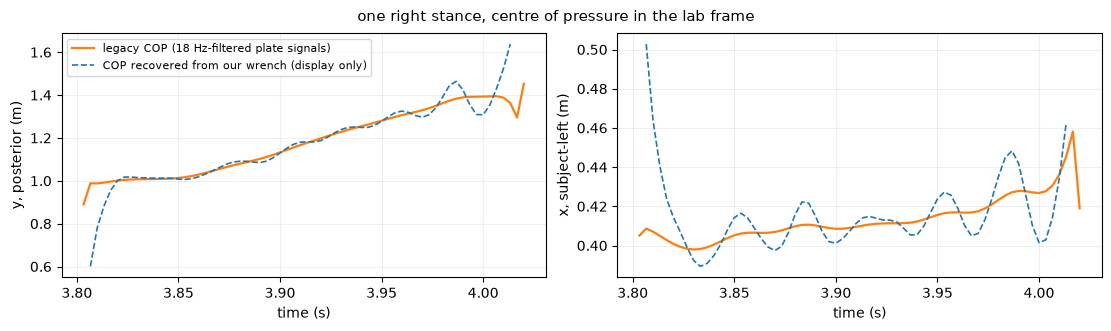

In [13]:
from boneid.core import cop_from_wrench

hs_ours = np.array([s for s, _ in steps]); to_ours = np.array([e for _, e in steps])
n = min(len(hs_ours), len(legacy.hs))
# align the two event lists on the first common stance
k0 = int(np.argmin(np.abs(legacy.hs - hs_ours[0])))
pairs = list(zip(legacy.hs[k0:k0 + n], hs_ours[:n], legacy.to[k0:k0 + n], to_ours[:n]))
d_hs = np.array([(a - b) / trial.rate * 1000 for a, b, _, _ in pairs])
d_to = np.array([(c - d) / trial.rate * 1000 for _, _, c, d in pairs])
display({"right_stances": {"legacy": int(len(legacy.hs)), "ours": int(len(steps))},
         "heel_strike_legacy_minus_ours_ms": {"mean": round(float(d_hs.mean()), 1), "sd": round(float(d_hs.std()), 1)},
         "toe_off_legacy_minus_ours_ms": {"mean": round(float(d_to.mean()), 1), "sd": round(float(d_to.std()), 1)},
         "first_five_legacy_HS_TO_frames": list(zip(legacy.hs[:5].tolist(), legacy.to[:5].tolist()))})

s0, e0 = legacy.hs[k0 + 5], legacy.to[k0 + 5]
cop_ours, _ = cop_from_wrench(ground.force, ground.moment, ground.point, plane_height=-0.0464)
cop_leg = lab_from_simm(legacy.cop)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), layout="constrained")
for ax, c, lab in ((axes[0], 1, "y, posterior (m)"), (axes[1], 0, "x, subject-left (m)")):
    ax.plot(trial.t[s0:e0 + 1], cop_leg[s0:e0 + 1, c], color="tab:orange", lw=1.6, label="legacy COP (18 Hz-filtered plate signals)")
    ax.plot(trial.t[s0:e0 + 1], cop_ours[s0:e0 + 1, c], color="tab:blue", lw=1.2, ls="--", label="COP recovered from our wrench (display only)")
    ax.set(xlabel="time (s)", ylabel=lab); ax.grid(alpha=0.2)
axes[0].legend(fontsize=8); fig.suptitle("one right stance, centre of pressure in the lab frame", fontsize=11)
plt.show()

## 14 — The MATLAB's exported moments over ours

What the MATLAB wrote to its spreadsheets and SIMM files was each stance's joint moment, filtered at 12 Hz *after* the recursion and resampled to 0–100 % of stance. The port produces exactly that. Below, those curves are rotated into our lab frame (their SIMM z, subject-right, is our −x) and drawn over our torques on the same stance windows, as mean ± SD across the 17 steps the script kept.

Both are the wrench on the distal segment from the proximal one, about the joint centre, sagittal component, so the signs agree without any convention gymnastics. Whatever's left is a real difference between the two analyses, and §15 goes through it.

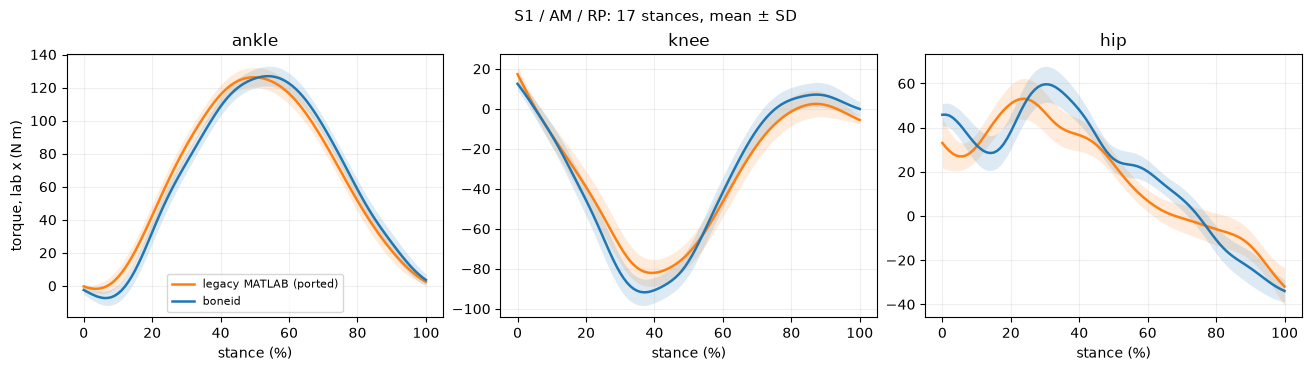

{'ankle': {'rms_diff_Nm': 7.5,
  'peak_legacy_Nm': 126.2,
  'peak_ours_Nm': 126.9,
  'r': 0.988},
 'knee': {'rms_diff_Nm': 7.0,
  'peak_legacy_Nm': 82.1,
  'peak_ours_Nm': 91.8,
  'r': 0.99},
 'hip': {'rms_diff_Nm': 10.8,
  'peak_legacy_Nm': 53.1,
  'peak_ours_Nm': 59.6,
  'r': 0.933}}

{'as_exported_by_the_script (local SIMM z, per-stance peak, mean over kept steps, N m)': {'mtp': -6.7,
  'ankle': -121.3,
  'knee': 75.3,
  'hip': -52.6}}

In [14]:
from scipy.interpolate import PchipInterpolator

pct = np.arange(101)
leg_lab = legacy_stance_torque_lab(legacy)            # [T,3,3], 12 Hz per stance, zero elsewhere
good = [s for s in legacy.steps if not s["bad"]]

def stance_curves(y, steps_):
    out = []
    for s in steps_:
        sl = slice(s["hs"], s["to"] + 1)
        x = np.linspace(0, 100, s["to"] - s["hs"] + 1)
        out.append(PchipInterpolator(x, y[sl], axis=0)(pct))
    return np.asarray(out)

names = skeleton.joint_names
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), layout="constrained")
summary = {}
for j, name in enumerate(names):
    a = stance_curves(leg_lab[:, j, 0], good)              # legacy, lab x
    b = stance_curves(idres.joint_torque[:, j, 0], good)   # ours, lab x, same windows
    for arr, col, lab in ((a, "tab:orange", "legacy MATLAB (ported)"), (b, "tab:blue", "boneid")):
        m, sd = arr.mean(axis=0), arr.std(axis=0)
        axes[j].plot(pct, m, color=col, lw=1.8, label=lab)
        axes[j].fill_between(pct, m - sd, m + sd, color=col, alpha=0.15, lw=0)
    axes[j].set(title=f"{name}", xlabel="stance (%)", ylabel="torque, lab x (N m)" if j == 0 else "")
    axes[j].grid(alpha=0.2)
    summary[name] = {"rms_diff_Nm": round(float(np.sqrt(np.mean((a - b) ** 2))), 1),
                     "peak_legacy_Nm": round(float(np.abs(a.mean(axis=0)).max()), 1),
                     "peak_ours_Nm": round(float(np.abs(b.mean(axis=0)).max()), 1),
                     "r": round(float(np.corrcoef(a.ravel(), b.ravel())[0, 1]), 3)}
axes[0].legend(fontsize=8)
fig.suptitle(f"{SUBJECT} / {CONDITION} / {TRIAL}: {len(good)} stances, mean ± SD", fontsize=11)
plt.show()
display(summary)
display({"as_exported_by_the_script (local SIMM z, per-stance peak, mean over kept steps, N m)":
         {j: round(float(np.mean([s["peak_local_moment"][j][2] for s in good])), 1) for j in ("mtp", "ankle", "knee", "hip")}})

## 15 — A ladder from their equations to ours

Same port, one change per rung. Rung 2 swaps only the three equations the rewrite fixed (inertia by the similarity transform, angular velocity from `Ṙ Rᵀ`, gyroscopic term kept) and puts the free moment on the vertical axis. Rung 3 also low-passes the markers at 12 Hz before anything gets differentiated, which the MATLAB never did. The table gives each rung's RMS distance from ours. What's left after the last rung is modelling choices: anthropometrics (Vaughan vs de Leva; the thigh alone is 5.2 kg vs 7.1 kg at this body mass), the COM fractions, the rearfoot/forefoot foot model, COP vs wrench, and the 5 N vs 50 N stance edges.

The figure shows why the MATLAB's after-the-fact 12 Hz filter was doing a lot of heavy lifting: the hip moment straight out of its recursion (twice-differentiated raw markers at 300 Hz), the same curve after the per-stance filter, and ours.

rung,ankle RMS,peak,knee RMS,peak,hip RMS,peak
1 legacy as written,7.5,126,7.0,82,10.8,53
2 + corrected physics & free-moment axis,6.1,125,5.9,87,6.0,59
3 + markers low-passed at 12 Hz,6.1,125,5.7,87,8.6,54
boneid (reference),—,127,—,92,—,60


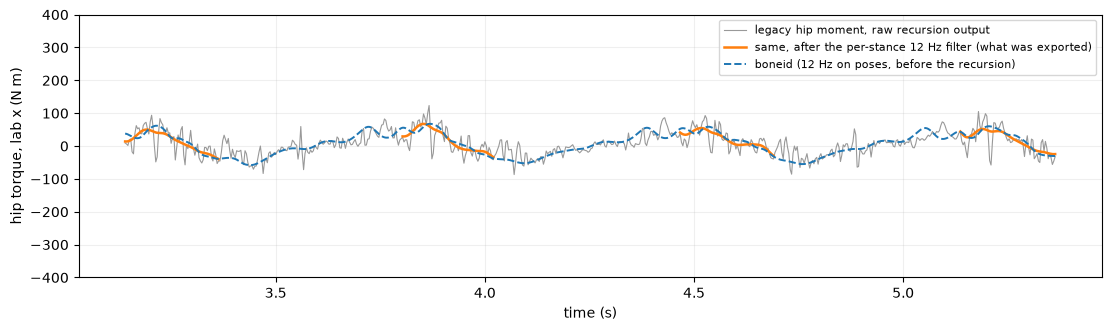

raw legacy hip moment: peak |M| 123 N m; after per-stance filtering 67 N m


In [15]:
ladder = {
    "1  legacy as written": legacy,
    "2  + corrected physics & free-moment axis": run_legacy_pipeline(
        static_raw, trial_raw, CONDITION, TRIAL, anthro_overrides={1: cal.body_mass},
        physics="corrected", free_moment_axis="y"),
    "3  + markers low-passed at 12 Hz": run_legacy_pipeline(
        static_raw, trial_raw, CONDITION, TRIAL, anthro_overrides={1: cal.body_mass},
        physics="corrected", free_moment_axis="y", marker_lowpass_hz=12.0),
}
rows = []
for label, r in ladder.items():
    lab_r = legacy_stance_torque_lab(r)
    good_r = [s for s in r.steps if not s["bad"]]
    cells_ = []
    for j, name in enumerate(names):
        a = stance_curves(lab_r[:, j, 0], good_r); b = stance_curves(idres.joint_torque[:, j, 0], good_r)
        cells_.append(f"<td>{np.sqrt(np.mean((a - b) ** 2)):.1f}</td><td>{np.abs(a.mean(axis=0)).max():.0f}</td>")
    rows.append(f"<tr><td>{label}</td>{''.join(cells_)}</tr>")
ours_row = "".join(f"<td>—</td><td>{np.abs(stance_curves(idres.joint_torque[:, j, 0], good).mean(axis=0)).max():.0f}</td>" for j in range(3))
display(HTML("<table><caption>RMS distance from boneid (N m) and mean-curve peak (N m), sagittal lab-x, per-stance 12 Hz filtered</caption>"
             "<thead><tr><th>rung</th><th>ankle RMS</th><th>peak</th><th>knee RMS</th><th>peak</th><th>hip RMS</th><th>peak</th></tr></thead><tbody>"
             + "".join(rows) + f"<tr><td>boneid (reference)</td>{ours_row}</tr></tbody></table>"))

w0, w1 = legacy.hs[k0 + 4], legacy.to[k0 + 7]
raw_hip = lab_from_simm(legacy.global_moment["hip"])[:, 0]
fig, ax = plt.subplots(figsize=(11, 3.2), layout="constrained")
ax.plot(trial.t[w0:w1], raw_hip[w0:w1], color="0.6", lw=0.8, label="legacy hip moment, raw recursion output")
ax.plot(trial.t[w0:w1], np.where(leg_lab[w0:w1, 2, 0] != 0, leg_lab[w0:w1, 2, 0], np.nan), color="tab:orange", lw=1.8, label="same, after the per-stance 12 Hz filter (what was exported)")
ax.plot(trial.t[w0:w1], idres.joint_torque[w0:w1, 2, 0], color="tab:blue", lw=1.4, ls="--", label="boneid (12 Hz on poses, before the recursion)")
ax.set(xlabel="time (s)", ylabel="hip torque, lab x (N m)"); ax.grid(alpha=0.2); ax.legend(fontsize=8)
ax.set_ylim(-400, 400)
plt.show()
print(f"raw legacy hip moment: peak |M| {np.abs(raw_hip[w0:w1]).max():.0f} N m; after per-stance filtering {np.abs(leg_lab[w0:w1, 2, 0]).max():.0f} N m")

## 16 — The real MATLAB, actually run

Everything above used the Python port. This closes the loop: `matlab-inverse-dynamics/harness/run_legacy_trial.m` runs the script's inverse-dynamics lines verbatim, calling the recovered `VirtualPoint_v2`, `getViconForces_Motek`, `ContactEvents_Motek`, `RoomSegAng`, `inv3d`, `G2L`, `multiprod`, `matexp`, `filterdata` and the rest, on the same two c3d files (handed over as `.mat`, since there's no Mac build of the ezc3d MEX). Its outputs are committed as `data/asics/matlab_reference/S1_AM_RP_legacy.mat` (MATLAB R2024b) and get regenerated here when MATLAB is available and `RUN_MATLAB` is set.

Port vs MATLAB at every stage: events, the recursion's raw global moments, and the exported per-stance curves. They agree to ~1e-11 N m, so the differences in §14–15 are differences between two analyses, not two implementations.

{'matlab': '24.2.0.2863752 (R2024b) Update 5',
 'generated': '2026-09-14 20:19:44',
 'events_identical': True,
 'max|GlobalMankle − port| (N m)': 1.7109869077103212e-11,
 'max|GlobalMknee − port| (N m)': 2.6897595262198593e-11,
 'max|GlobalMhip − port| (N m)': 6.037126354385691e-11,
 'max|step_ankle_Mloc − port| (N m, exported per-stance)': 4.46931380793103e-12,
 'max|step_knee_Mloc − port| (N m, exported per-stance)': 5.265121671982342e-12,
 'max|step_hip_Mloc − port| (N m, exported per-stance)': 4.163780431554187e-11}

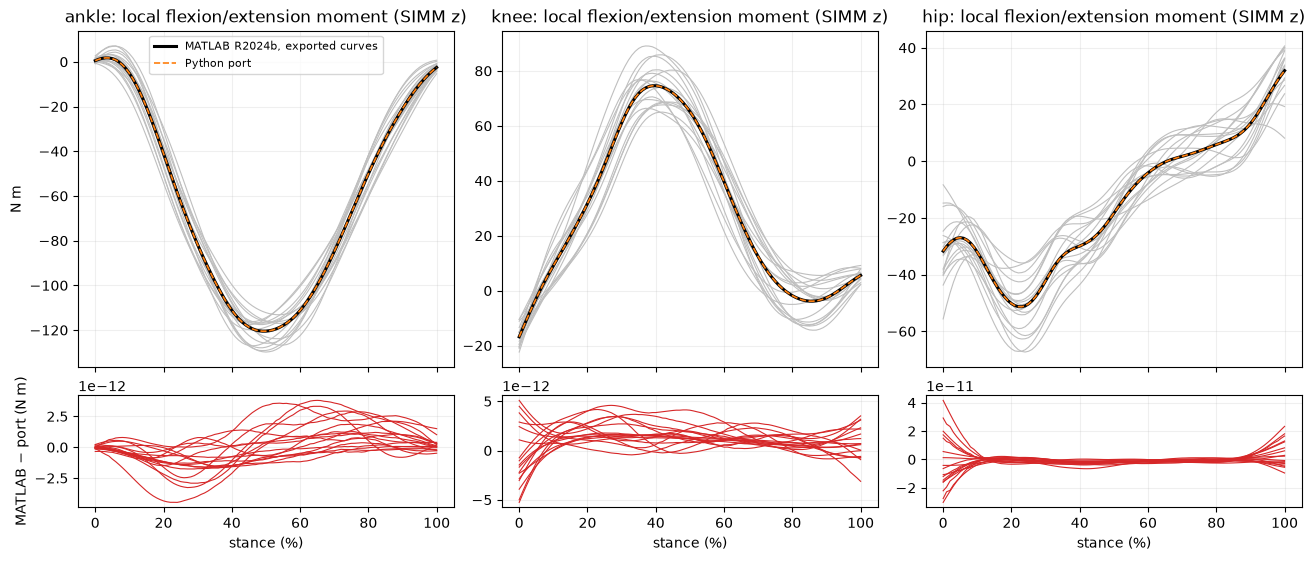

In [16]:
import os
from boneid.legacy import (MATLAB_BIN, MATLAB_REFERENCE, load_matlab_reference,
                           run_matlab_legacy, save_matlab_reference)

RUN_MATLAB = False        # True: re-execute the original routines in MATLAB (~1 min) and refresh the reference
ref_path = ROOT / MATLAB_REFERENCE / f"{SUBJECT}_{CONDITION}_{TRIAL}_legacy.mat"
if RUN_MATLAB and os.path.exists(MATLAB_BIN):
    m = run_matlab_legacy(DATA_DIR / f"{SUBJECT}_{CONDITION}_Static.c3d", DATA_DIR / f"{SUBJECT}_{CONDITION}_{TRIAL}.c3d",
                          CONDITION, TRIAL, ref_path.with_suffix(".full.mat"), body_mass=cal.body_mass)
    save_matlab_reference(m, ref_path)
matlab = load_matlab_reference(ref_path)
hs_m, to_m = matlab["HS"].astype(int) - 1, matlab["TO"].astype(int) - 1
mask_m = np.zeros(len(trial.t), bool)
for s_, e_ in zip(hs_m, to_m):
    mask_m[s_:e_ + 1] = True
parity = {"matlab": str(matlab["matlab_version"]), "generated": str(matlab["generated"]),
          "events_identical": bool(np.array_equal(hs_m, legacy.hs) and np.array_equal(to_m, legacy.to))}
for key, joint in (("GlobalMankle", "ankle"), ("GlobalMknee", "knee"), ("GlobalMhip", "hip")):
    parity[f"max|{key} − port| (N m)"] = float(np.abs(np.asarray(matlab[key]) - legacy.global_moment[joint])[mask_m].max())
for key, joint in (("step_ankle_Mloc", "ankle"), ("step_knee_Mloc", "knee"), ("step_hip_Mloc", "hip")):
    ours_ = np.stack([s["local_moment"][joint] for s in legacy.steps])
    parity[f"max|{key} − port| (N m, exported per-stance)"] = float(np.abs(np.asarray(matlab[key]) - ours_).max())
display(parity)

fig, axes = plt.subplots(2, 3, figsize=(13, 5.5), layout="constrained", sharex=True, height_ratios=(3, 1))
for j, (key, joint) in enumerate((("step_ankle_Mloc", "ankle"), ("step_knee_Mloc", "knee"), ("step_hip_Mloc", "hip"))):
    a = np.asarray(matlab[key])[:, :, 2]; b = np.stack([s["local_moment"][joint][:, 2] for s in legacy.steps])
    keep = ~np.asarray(matlab["step_bad"]).astype(bool)
    axes[0, j].plot(pct, a[keep].T, color="0.75", lw=0.8)
    axes[0, j].plot(pct, a[keep].mean(axis=0), color="k", lw=2.2, label="MATLAB R2024b, exported curves")
    axes[0, j].plot(pct, b[keep].mean(axis=0), color="tab:orange", lw=1.2, ls="--", label="Python port")
    axes[0, j].set(title=f"{joint}: local flexion/extension moment (SIMM z)", ylabel="N m" if j == 0 else "")
    axes[1, j].plot(pct, (a - b)[keep].T, color="tab:red", lw=0.8)
    axes[1, j].set(xlabel="stance (%)", ylabel="MATLAB − port (N m)" if j == 0 else "")
    for ax in axes[:, j]: ax.grid(alpha=0.2)
axes[0, 0].legend(fontsize=8)
plt.show()

## Part 3 — the report

## 17 — Build the interactive viewer

`c3d_viewer_html` returns the viewer as an HTML string; it's embedded in the report below, where you can play, pause and scrub it.

In [17]:
viewer_html = c3d_viewer_html(trial, cal, skeleton, kin, ground, quality, params)
print(f"viewer_html: {type(viewer_html).__name__}, {len(viewer_html):,} characters")


viewer_html: str, 1,547,007 characters


## 18 — Generate the report HTML

`c3d_report_html` puts together the figures, animation, energy audit and tables from Part 1.

In [18]:
html = c3d_report_html(
    trial, static, cal, skeleton, kin, ground, quality, idres, audit,
    params, viewer_html=viewer_html,
    title=f"The report: {SUBJECT}, shoe {CONDITION}, trial {TRIAL}",
    source_note=f"Subject {SUBJECT}, shoe condition {CONDITION}, trial {TRIAL}.")
print(f"html: {type(html).__name__}, {len(html):,} characters")

html: str, 6,684,739 characters


## 19 — The finished report

The figures cited in the findings above (Fig. 3 torques, Fig. 5 foot work, Fig. 8 energy audit) are in here. To rebuild the exported page: `uv run python examples/regenerate_reports.py asics_running_c3d`.


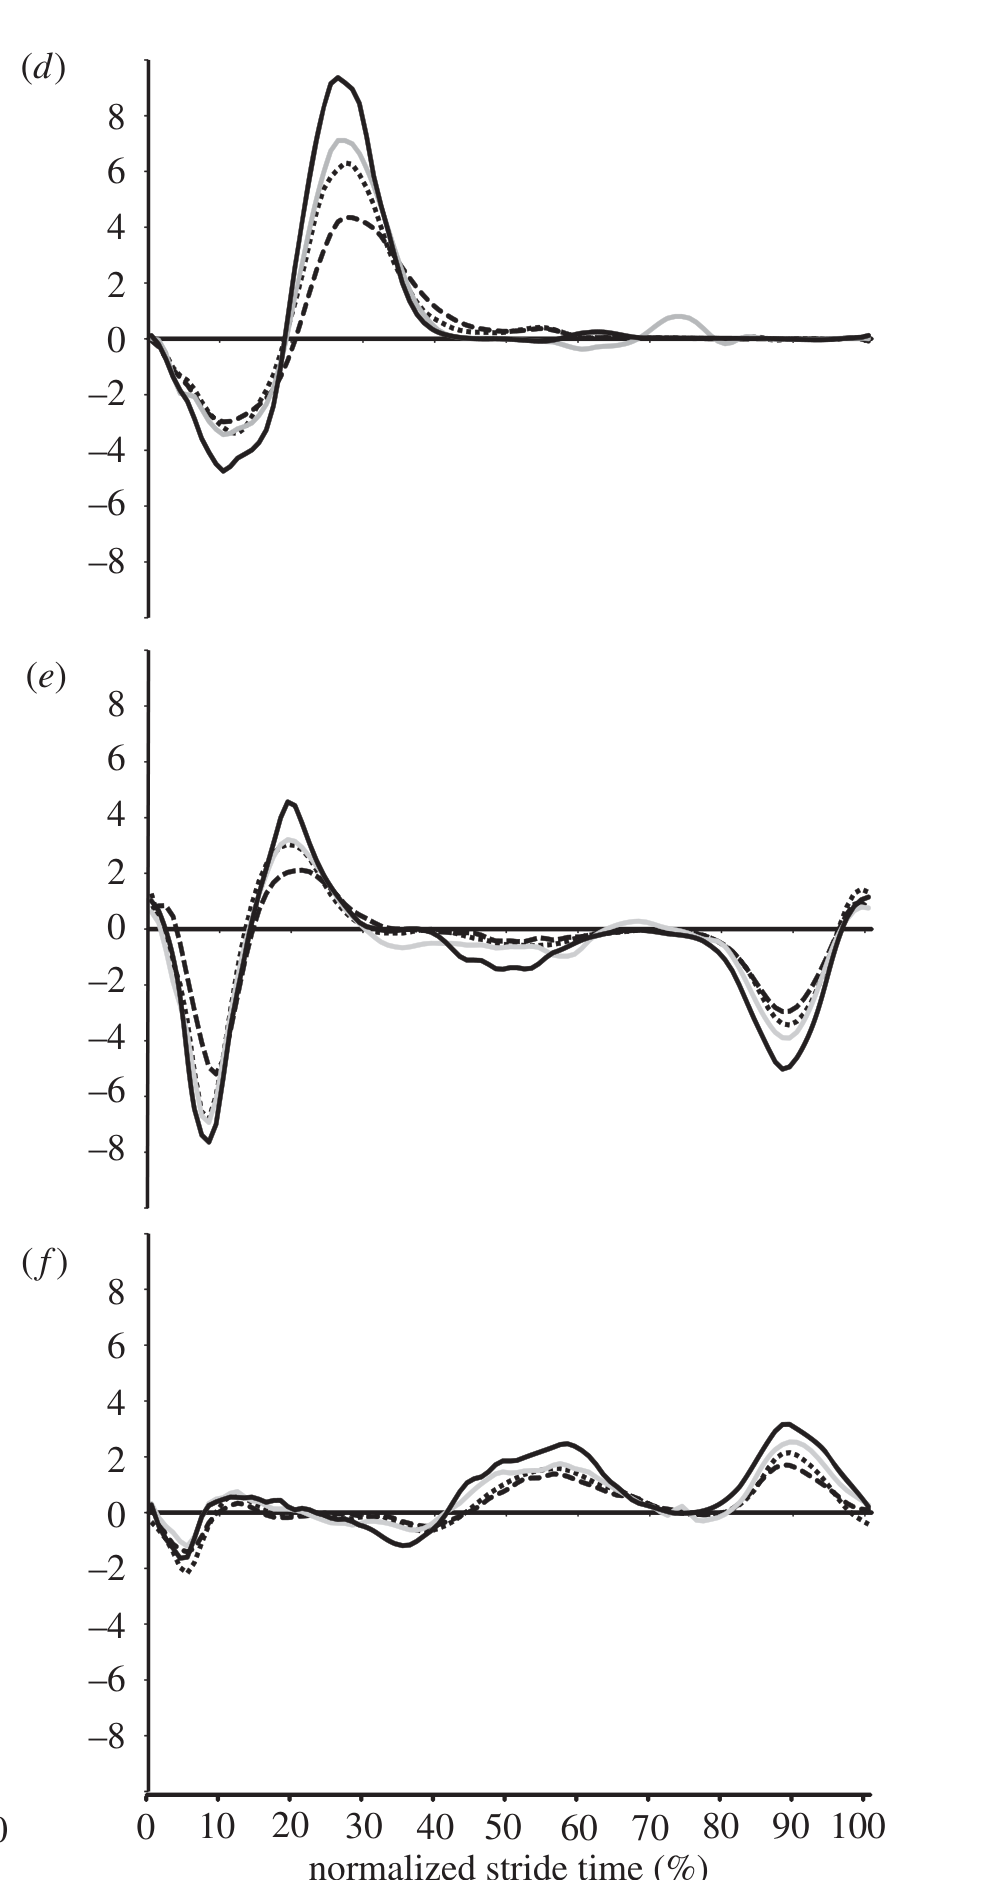

In [19]:
display(HTML(html))
